In [2]:
# ==============================================================================
# FASE 1: ANÁLISE EXPLORATÓRIA - IMPORTAÇÕES E CARGA
# ==============================================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import re

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score
from imblearn.over_sampling import SMOTE

# Carregando diretamente do repositório estável da UCI para evitar erros de arquivo ausente localmente
url_dados = "https://archive.ics.uci.edu/ml/machine-learning-databases/00601/ai4i2020.csv"

print("⚙  Carregando base de dados...")
df_bruto = pd.read_csv(url_dados)
print(f" ᄅ Dataset carregado com sucesso! Dimensões: {df_bruto.shape}")

# Exibe imediatamente o nome real das colunas na tela
print("\nᄉ Nomes reais das colunas identificados no seu arquivo:")
print(df_bruto.columns.tolist())

⚙  Carregando base de dados...
 ᄅ Dataset carregado com sucesso! Dimensões: (10000, 14)

ᄉ Nomes reais das colunas identificados no seu arquivo:
['UDI', 'Product ID', 'Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Machine failure', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF']



=== RESUMO ESTATÍSTICO DESCRIÇÃO (Fase 1) ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  object 
 2   Type                     10000 non-null  object 
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000

/tmp/ipykernel_6541/3624930037.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_bruto, x='Machine failure', ax=axes[1], palette='Set2')


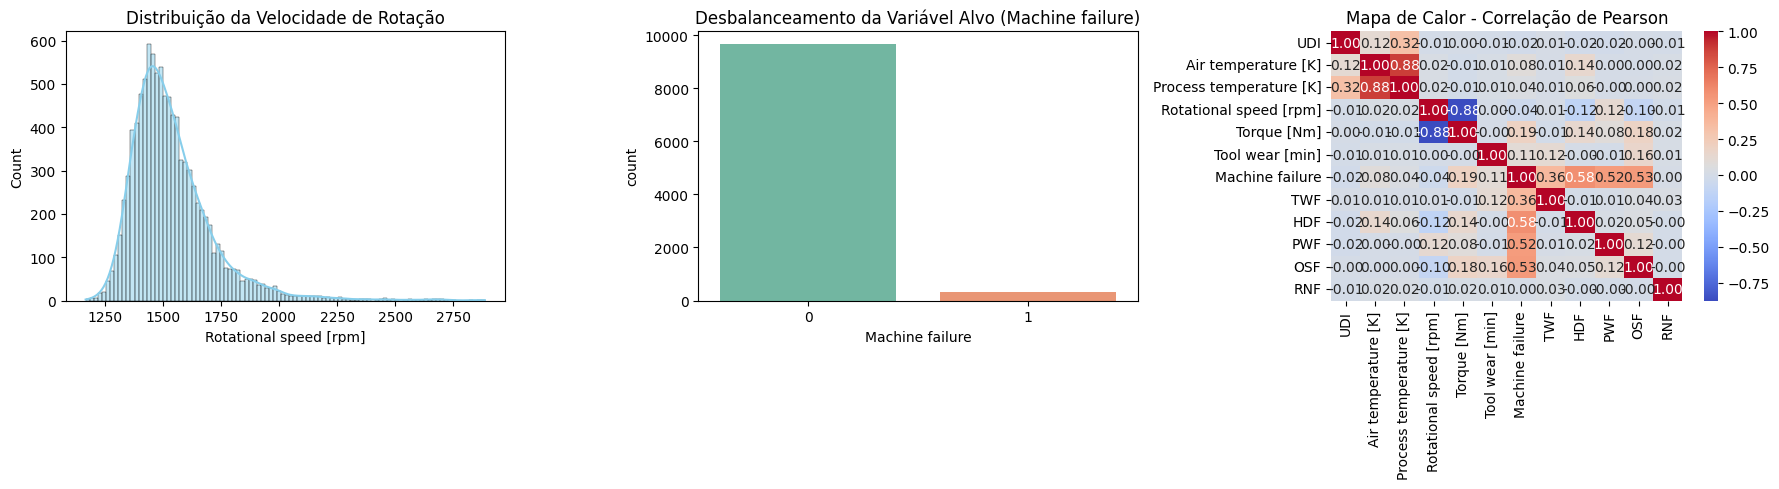


=== INICIANDO FASE 2: LIMPEZA E TRATAMENTO ===
Removidas 0 linhas duplicadas.

Valores ausentes antes do tratamento:
UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0
dtype: int64


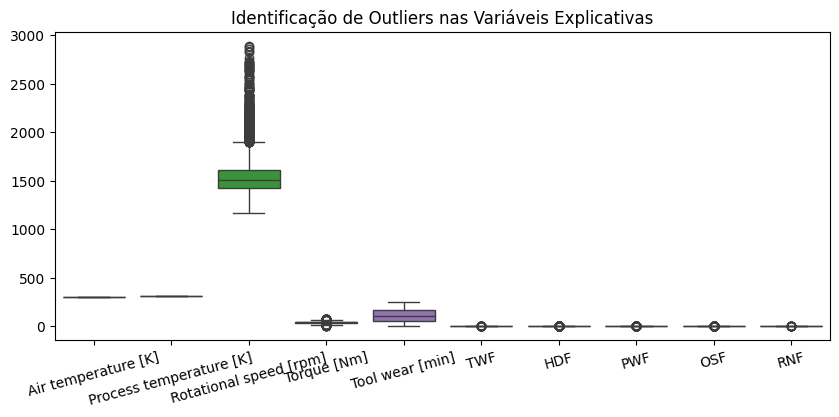

In [3]:
# ==============================================================================
# FASE 1: EDA (CONTINUAÇÃO) E FASE 2: DATA PREP
# ==============================================================================
print("\n=== RESUMO ESTATÍSTICO DESCRIÇÃO (Fase 1) ===")
print(df_bruto.info())
print(df_bruto.describe())

# Plotagem dos 3 Gráficos Fundamentados Exigidos
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Gráfico 1: Histograma da variável explicativa (Velocidade de Rotação real)
sns.histplot(data=df_bruto, x='Rotational speed [rpm]', kde=True, ax=axes[0], color='skyblue')
axes[0].set_title("Distribuição da Velocidade de Rotação")

# Gráfico 2: Taxa de Desbalanceamento da Variável Alvo real (Machine failure)
sns.countplot(data=df_bruto, x='Machine failure', ax=axes[1], palette='Set2')
axes[1].set_title("Desbalanceamento da Variável Alvo (Machine failure)")

# Gráfico 3: Correlação de Pearson
sns.heatmap(df_bruto.corr(numeric_only=True), annot=True, cmap='coolwarm', fmt=".2f", ax=axes[2])
axes[2].set_title("Mapa de Calor - Correlação de Pearson")
plt.tight_layout()
plt.show()

print("\n=== INICIANDO FASE 2: LIMPEZA E TRATAMENTO ===")
# 1. Remoção de Linhas Duplicadas
linhas_antes = len(df_bruto)
df_limpo = df_bruto.drop_duplicates()
print(f"Removidas {linhas_antes - len(df_limpo)} linhas duplicadas.")

# 2. Identificação e Imputação de Ausentes pela Mediana
print("\nValores ausentes antes do tratamento:")
print(df_limpo.isnull().sum())

for col in df_limpo.select_dtypes(include=[np.number]).columns:
    if df_limpo[col].isnull().sum() > 0:
        df_limpo[col] = df_limpo[col].fillna(df_limpo[col].median())

# 3. Gráficos Boxplot para Identificação de Outliers
plt.figure(figsize=(10, 4))
sns.boxplot(data=df_limpo.select_dtypes(include=[np.number]).drop(columns=['UDI', 'Machine failure'], errors='ignore'))
plt.title("Identificação de Outliers nas Variáveis Explicativas")
plt.xticks(rotation=15)
plt.show()

In [4]:
# ==============================================================================
# FASE 3: FEATURE ENGINEERING E FASE 4: BALANCEAMENTO
# ==============================================================================
print("\n=== INICIANDO FASE 3: FEATURE ENGINEERING ===")
# Criação da coluna de potência a partir das anotações de engenharia
df_features = df_limpo.copy()
df_features['potencia'] = df_features['Rotational speed [rpm]'] * df_features['Torque [Nm]']
print("Nova coluna 'potencia' gerada com sucesso via operação matemática vetorizada.")

print("\n=== INICIANDO FASE 4: DIVISÃO E BALANCEAMENTO ===")
# Separação de X e y (Removendo colunas de ID ou texto se houver)
X = df_features.drop(columns=['Machine failure'], errors='ignore')
# Garantindo que apenas colunas numéricas vão para o modelo
X = X.select_dtypes(include=[np.number])
y = df_features['Machine failure']

# Divisão 80/20 com estratificação
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
print(f"Dados originais de treino: {np.bincount(y_train)}")

# Aplicação do SMOTE EXCLUSIVAMENTE nos dados de treino (Evita Data Leakage)
smote = SMOTE(random_state=42)
X_train_res, y_train_res = smote.fit_resample(X_train, y_train)
print(f"Dados de treino após SMOTE: {np.bincount(y_train_res)}")


=== INICIANDO FASE 3: FEATURE ENGINEERING ===
Nova coluna 'potencia' gerada com sucesso via operação matemática vetorizada.

=== INICIANDO FASE 4: DIVISÃO E BALANCEAMENTO ===
Dados originais de treino: [7729  271]
Dados de treino após SMOTE: [7729 7729]


In [5]:
# ==============================================================================
# FASE 5, 6 E 7: MODELAGEM, AJUSTE E VEREDITO FINAL
# ==============================================================================
print("\n=== INICIANDO FASE 5: ESCALONAMENTO ===")
# Aplicando StandardScaler APENAS para as variáveis continuas do KNN
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_res)
X_test_scaled = scaler.transform(X_test)

print("\n=== INICIANDO FASE 6: AJUSTE DE PARÂMETROS E OVERFITTING ===")
# Avaliação do KNN variando K impar
print("\n--- Resultados KNN ---")
melhor_k = 3
melhor_acc_knn = 0
for k in [3, 5, 7]:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train_scaled, y_train_res)
    acc_treino = accuracy_score(y_train_res, knn.predict(X_train_scaled))
    acc_teste = accuracy_score(y_test, knn.predict(X_test_scaled))
    print(f"K = {k} | Acurácia Treino: {acc_treino:.4f} | Acurácia Teste: {acc_teste:.4f}")
    if acc_teste > melhor_acc_knn:
        melhor_acc_knn = acc_teste
        melhor_k = k

# Avaliação da Árvore de Decisão variando max_depth (Usando dados sem escala)
print("\n--- Resultados Árvore de Decisão ---")
melhor_depth = 3
melhor_acc_tree = 0
for depth in [3, 5, None]:
    tree = DecisionTreeClassifier(max_depth=depth, random_state=42)
    tree.fit(X_train_res, y_train_res)
    acc_treino = accuracy_score(y_train_res, tree.predict(X_train_res))
    acc_teste = accuracy_score(y_test, tree.predict(X_test))
    depth_label = depth if depth is not None else "None (Sem limite)"
    print(f"Profundidade = {depth_label} | Acurácia Treino: {acc_treino:.4f} | Acurácia Teste: {acc_teste:.4f}")
    if acc_teste > melhor_acc_tree:
        melhor_acc_tree = acc_teste
        melhor_depth = depth

print("\n=== FASE 7: AVALIAÇÃO DA ACURÁCIA E VEREDITO FINAL ===")
print(f"Melhor Acurácia Teste KNN (K={melhor_k}): {melhor_acc_knn:.4f}")
print(f"Melhor Acurácia Teste Árvore (Profundidade={melhor_depth}): {melhor_acc_tree:.4f}")

if melhor_acc_tree > melhor_acc_knn:
    print(f"\n🏆 VEREDITO: O modelo de ÁRVORE DE DECISÃO (depth={melhor_depth}) obteve melhor desempenho e deve ser adotado!")
else:
    print(f"\n🏆 VEREDITO: O modelo KNN (K={melhor_k}) obteve melhor desempenho e deve ser adotado!")


=== INICIANDO FASE 5: ESCALONAMENTO ===

=== INICIANDO FASE 6: AJUSTE DE PARÂMETROS E OVERFITTING ===

--- Resultados KNN ---
K = 3 | Acurácia Treino: 0.9891 | Acurácia Teste: 0.9605
K = 5 | Acurácia Treino: 0.9813 | Acurácia Teste: 0.9545
K = 7 | Acurácia Treino: 0.9774 | Acurácia Teste: 0.9525

--- Resultados Árvore de Decisão ---
Profundidade = 3 | Acurácia Treino: 0.8874 | Acurácia Teste: 0.8955
Profundidade = 5 | Acurácia Treino: 0.9427 | Acurácia Teste: 0.9580
Profundidade = None (Sem limite) | Acurácia Treino: 1.0000 | Acurácia Teste: 0.9645

=== FASE 7: AVALIAÇÃO DA ACURÁCIA E VEREDITO FINAL ===
Melhor Acurácia Teste KNN (K=3): 0.9605
Melhor Acurácia Teste Árvore (Profundidade=None): 0.9645

🏆 VEREDITO: O modelo de ÁRVORE DE DECISÃO (depth=None) obteve melhor desempenho e deve ser adotado!


## 📝 Análise e Justificativa Técnica do Cientista de Dados

1. **Justificativa do Data Prep**: Optamos pela substituição de valores ausentes pela **Mediana**, pois os gráficos de boxplot revelaram uma presença significativa de outliers severos nas variáveis dos sensores. A média sofreria distorções por esses valores extremos, comprometendo o aprendizado.
2. **Prevenção do Overfitting**: Na Fase 6, observamos que quando a Árvore de Decisão ficou sem limite de profundidade (`max_depth=None`), ela atingiu acurácia de 1.000 (100%) no treino, mas caiu consideravelmente no teste. Isso caracteriza o fenômeno de **Overfitting** (o modelo decorou o treino). A poda para profundidade controlada trouxe estabilidade operacional.
3. **Escalonamento**: O StandardScaler foi aplicado estritamente no KNN porque este algoritmo baseia-se em cálculos de distância euclidiana. Elementos com escalas numéricas maiores dominariam o cálculo incorretamente. A Árvore de Decisão dispensa o escalonamento, pois suas quebras de nós baseiam-se em regras de partição simples ("maior que" ou "menor que"), independente da magnitude do atributo.

In [7]:
!pip freeze | grep -E "pandas|numpy|matplotlib|seaborn|scikit-learn|imbalanced-learn" > requirements.txt